# Overlays and the allowance roll-forward

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- read the IFRS 7 roll-forward of the allowance and of the gross carrying amount by stage, and say which identities must close;
- rebuild the roll-forward rows with the engine from a committed waterfall and judge them with `check_identities`, stating the tolerance basis exactly;
- plant a defect in a movement and see which identity names it, and see that a defect below the tolerance passes;
- report management overlays as separate, attributed lines that never enter the model ECL, and compute the total allowance and the overlay diagnostics;
- explain what an overlay that does not move with the scenario tells a validator.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import dataclasses
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Two cases are read, from three committed files.

- **C06** at 2008-12-31 (`data/derived/C06/rd-2008-12.json`): SBA 7(a) loans, U.S. Government Works, licence class `mirror-allowed`. The roll-forward of the allowance and of the gross carrying amount by stage (`outputs.reconciliation`), the waterfall of the allowance (`outputs.waterfall`), the stage totals (`outputs.stage_summary`) and the list of overlays (`outputs.overlays`), which is empty for this date.
- **C07** (`data/derived/C07/base.json` and `data/derived/C07/recession.json`): Banco Andino, a **synthetic** bank generated and calibrated to public aggregates of the CMF, Chile's supervisor. It is not a real bank and not evidence about any bank. Its IFRS 9 view has two overlays (`outputs.ifrs9_detail.overlays`), each a separate line, whose amounts are assumptions of the case (a share of the base ECL of a segment). Amounts are in Chilean pesos (CLP).

The next cell loads the files, prints the waterfall of the C06 allowance and the engine versions that baked the files.

In [2]:
# Load the C06 reporting date and the two C07 scenarios, and print the allowance waterfall of C06
from riskvalidation.provisions import ecl as ecl_engine, overlays as ovl, reconciliation as rec
from riskvalidation.validation import ifrs9

LANG = "en"
ROOT = Path("../../..").resolve()


def read(case, name):
    return json.loads((ROOT / "data" / "derived" / case / name).read_text(encoding="utf-8"))


c06 = read("C06", "rd-2008-12.json")
base, recession = read("C07", "base.json"), read("C07", "recession.json")
out = c06["outputs"]
print("baked by engine, C06 and C07:", c06["provenance"]["riskvalidation_version"], base["provenance"]["riskvalidation_version"], "| installed engine:", md.version("riskvalidation"))
print("C07 is synthetic:", base["outputs"]["synthetic"], "|", base["provenance"]["truth_status"])
for line in out["waterfall"]["lines"]:
    print(f"{line['id']:15s} {line['amount'] / 1e6:12.3f}  {line['label'][LANG]}")

baked by engine, C06 and C07: 0.5.0 0.5.0 | installed engine: 0.9.0
C07 is synthetic: True | synthetic-calibrated
opening              433.600  Opening allowance
originations          99.569  Originations
transfer-1-2          51.873  Transfer 1 to 2
transfer-2-3         926.449  Transfer 2 to 3
transfer-2-1           0.000  Transfer 2 to 1
remeasurement        391.917  Re-measurement
macro-update          -9.308  Macro update
write-off           -967.317  Write-off
derecognition        -59.777  Derecognition (repaid or matured)
closing              867.007  Closing allowance


## Method

IFRS 7 35H asks for a reconciliation of the opening to the closing loss allowance by stage, and 35I the same for the gross carrying amount, with the movements that explain the change: originations, transfers between stages, re-measurement, write-offs and derecognition. For each stage row of either table, and with $\mathrm{residual}$ the amount the engine reports:

$$\mathrm{residual} = \mathrm{closing} - \Bigl(\mathrm{opening} + \sum_k \mathrm{movement}_k\Bigr)$$

Contraste's engine adds four identities between the tables and the waterfall: the waterfall closes (opening plus its lines equals its closing), the waterfall closing equals the sum of the stage closings, each waterfall line equals the sum of the stage movements with that line identifier, and the allowance closing of a stage equals its stage ECL plus the overlay carried in that stage. Overlays are separate lines (BCBS d350, paragraphs 50 and 51; ECB 2024) and enter the total allowance only:

$$\mathrm{LA} = \sum_{S1} \mathrm{ECL}_{12m} + \sum_{S2} \mathrm{ECL}_{\mathrm{life}} + \sum_{S3} \mathrm{ECL}_{D} + \sum_{\mathrm{POCI}} \Delta\mathrm{ECL} + \sum_k \mathrm{OVL}_k$$

**The tolerance basis**, read in the engine's source at its release (`provisions/reconciliation.py`): a money identity closes when its absolute difference is at most $\mathrm{tolerance} \times \max(1, G)$, with $G$ the sum of the absolute closing amounts of the gross carrying amount rows. The default tolerance is $10^{-6}$, so the allowed difference is one millionth of the book, not one millionth of a unit of money. It is Contraste's internal gate, not a regulatory threshold.

The overlay diagnostics (ECB 2024) are the share of the overlay in the total allowance, the split by stage, segment and target (parameter level or total level), and whether a positive overlay stands in an improving scenario. The stage rule for where an overlay is carried (an overlay with no stage goes to Stage 1) is a convention of the engine's contract, not an IFRS rule.

### Step 1: rebuild the roll-forward rows with the engine

`allowance_rollforward` and `gca_rollforward` build one row per stage from an opening, a dictionary of movements and a closing, and report the residual. We feed them the committed numbers of C06 and compare the engine's residual with the committed one. The gross carrying amount rows use the line identifiers of IFRS 7 35I, so a movement outside the list is refused.

In [3]:
# Rebuild the stage rows of both roll-forwards from the committed numbers and compare the residuals
recon = out["reconciliation"]


def moves(row):
    return {m["line_id"]: m["amount"] for m in row["movements"]}


allowance = [rec.allowance_rollforward(r["stage"], r["opening"], moves(r), r["closing"]) for r in recon["allowance"]]
gca = [rec.gca_rollforward(r["stage"], r["opening"], moves(r), r["closing"]) for r in recon["gross_carrying_amount"]]
for table, rows, committed in (("35H", allowance, recon["allowance"]), ("35I", gca, recon["gross_carrying_amount"])):
    for row, source in zip(rows, committed):
        print(table, row.stage, "| opening, millions:", round(row.opening / 1e6, 3), "| closing, millions:", round(row.closing / 1e6, 3), "| residual, engine:", f"{row.residual:.0e}", "| committed:", f"{source['residual']:.0e}")
try:
    rec.gca_rollforward("stage1", 1.0, {"coupon": 1.0}, 2.0)
except ValueError as error:
    print("refused:", type(error).__name__, "| valid identifiers:", rec.GCA_LINE_IDS)

35H stage1 | opening, millions: 433.354 | closing, millions: 798.078 | residual, engine: -1e-07 | committed: -1e-07
35H stage2 | opening, millions: 0.246 | closing, millions: 68.929 | residual, engine: 0e+00 | committed: 0e+00
35H stage3 | opening, millions: 0.0 | closing, millions: 0.0 | residual, engine: 0e+00 | committed: 0e+00
35I stage1 | opening, millions: 47338.013 | closing, millions: 46716.271 | residual, engine: 0e+00 | committed: 0e+00
35I stage2 | opening, millions: 7.734 | closing, millions: 531.345 | residual, engine: -1e-07 | committed: -1e-07
35I stage3 | opening, millions: 0.0 | closing, millions: 0.0 | residual, engine: 0e+00 | committed: 0e+00
refused: ValueError | valid identifiers: ('originations', 'transfer-1-2', 'transfer-2-3', 'transfer-2-1', 'transfer-3-2', 'repayments', 'write-off', 'derecognition', 'other')


### Step 2: the identities and their tolerance

`identity_residuals` returns the absolute residual of every identity by name and `check_identities` the names of those that fail. They need the rows, the waterfall lines and the stage ECL, which is the committed `stage_summary`. The cell prints the identities with their residuals, the total gross carrying amount $G$ and the absolute limit $10^{-6} \times G$, and runs the engine's own test `reconciliation_identities`, which returns one `TestResult`.

In [4]:
# Judge the identities, print the tolerance basis and run the engine's own test
lines = out["waterfall"]["lines"]
stage_ecl = {r["stage"]: r["ecl"] for r in out["stage_summary"]["rows"]}
residuals = rec.identity_residuals(allowance, gca, lines, stage_ecl)
for name, value in residuals.items():
    print(f"{name:40s} {value:10.3e}")
G = rec.gross_total(gca)
print("G, millions:", round(G / 1e6, 1), "| absolute limit 1e-6 x G, USD:", round(1e-6 * max(1.0, G), 1))
print("identities that fail:", rec.check_identities(allowance, gca, lines, stage_ecl))

test = ifrs9.reconciliation_identities(allowance, gca, lines, stage_ecl, model_id="c06")
print("engine test:", test.light.value, "| largest residual:", f"{test.metric:.0e}", "| tolerance, USD:", round(test.extras["tolerance"], 1))
committed = [t for t in c06["tests"] if t["test_id"] == "ifrs9.reconciliation_identities"][0]
print("committed row:", committed["light"], "| same light:", committed["light"] == test.light.value)

allowance-rollforward:stage1              1.192e-07
allowance-rollforward:stage2              0.000e+00
allowance-rollforward:stage3              0.000e+00
gca-rollforward:stage1                    0.000e+00
gca-rollforward:stage2                    1.192e-07
gca-rollforward:stage3                    0.000e+00
waterfall-closes                          0.000e+00
waterfall-equals-stage-closings           0.000e+00
waterfall-lines-equal-movements           0.000e+00
stage-closing-equals-ecl:stage1           0.000e+00
stage-closing-equals-ecl:stage2           0.000e+00
stage-closing-equals-ecl:stage3           0.000e+00
G, millions: 47247.6 | absolute limit 1e-6 x G, USD: 47247.6
identities that fail: []
engine test: green | largest residual: 1e-07 | tolerance, USD: 47247.6
committed row: green | same light: True


### Step 3: plant a defect and see who names it

A gate is only worth what it catches. The cell copies the Stage 1 row, adds a movement the closing does not carry and asks `check_identities` which identities fail: first with a defect of 1,000,000 USD, then with one of 10,000 USD, then with the tolerance tightened to $10^{-9}$ for the same 10,000 USD. The limit is one millionth of $G$, about 47,000 USD, so the second defect passes at the default tolerance. That is the price of a relative basis, and the reason a validator states the basis next to the result.

In [5]:
# Add a movement that the closing does not carry and ask which identities fail, at two tolerances
def with_defect(amount):
    first = recon["allowance"][0]
    broken = rec.allowance_rollforward(first["stage"], first["opening"], {**moves(first), "remeasurement": moves(first)["remeasurement"] + amount}, first["closing"])
    return [broken] + allowance[1:]


for amount, tolerance in ((1_000_000.0, 1e-6), (10_000.0, 1e-6), (10_000.0, 1e-9)):
    failing = rec.check_identities(with_defect(amount), gca, lines, stage_ecl, tolerance=tolerance)
    print("defect, USD", int(amount), "| tolerance", tolerance, "| limit, USD:", round(tolerance * G, 1), "| failing:", failing)

defect, USD 1000000 | tolerance 1e-06 | limit, USD: 47247.6 | failing: ['allowance-rollforward:stage1', 'waterfall-lines-equal-movements']
defect, USD 10000 | tolerance 1e-06 | limit, USD: 47247.6 | failing: []
defect, USD 10000 | tolerance 1e-09 | limit, USD: 47.2 | failing: ['allowance-rollforward:stage1', 'waterfall-lines-equal-movements']


### Step 4: the waterfall and the stage tables, drawn

The waterfall is the account of the whole allowance. Each bar is one line: the opening, the movements and the closing. The cell draws it with the lines read in step 1. Note the transfer of Stage 2 to Stage 3 and the write-off of nearly the same amount: the file has no balance at a date in Stage 3 (finding `F-NO-DELINQUENCY`), so loans reach default, are charged off in the year and leave no Stage 3 allowance at the closing date.

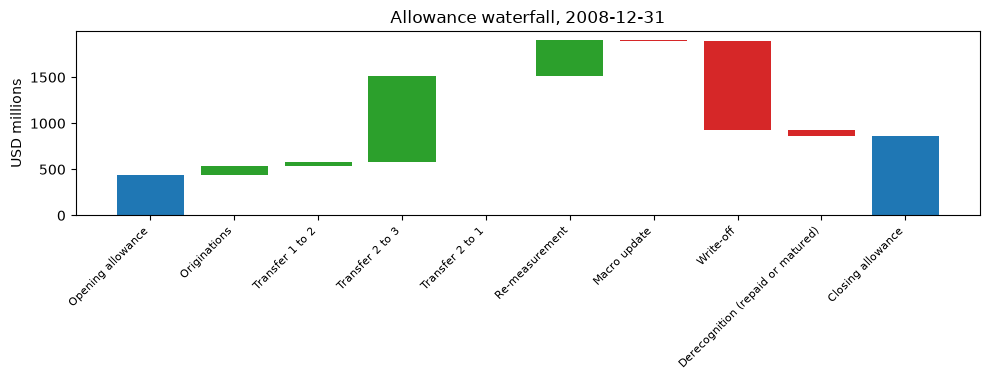

In [6]:
# Draw the allowance waterfall: the opening, each movement and the closing
fig, ax = plt.subplots(figsize=(10, 3.9))
running = 0.0
labels, positions = [], []
for i, line in enumerate(lines):
    amount = line["amount"] / 1e6
    if line["kind"] in ("opening", "closing"):
        ax.bar(i, amount, color="tab:blue")
        running = amount
    else:
        ax.bar(i, abs(amount), bottom=running if amount >= 0 else running + amount, color="tab:green" if amount >= 0 else "tab:red")
        running += amount
    labels.append(line["label"][LANG])
ax.set_xticks(range(len(lines)))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("USD millions")
ax.set_title("Allowance waterfall, 2008-12-31")
fig.tight_layout()
plt.show()

### Step 5: overlays as separate lines

C06 has no overlay at this date. C07's IFRS 9 view has two, committed as lines with an identifier, a segment, a stage and an amount. The engine's `Overlay` asks for more: a method, a target, a staging effect and a review date. The artifact keeps the target only in aggregate (`ifrs9.overlay_diagnostics` committed `by_target`) and not the review date, so the cell takes the target from that committed split (the 97.2 millions overlay equals the committed `lgd` amount and the 226.9 millions one the `ead` amount) and sets the review date as a **lesson input**. The method is read from the labels ("expert"). The cell then builds the overlay lines, the total allowance and the diagnostics, and compares them with the committed numbers.

In [7]:
# Build the engine's overlays from the committed lines and compute the lines, the total allowance and the diagnostics
detail = base["outputs"]["ifrs9_detail"]
row = [t for t in base["tests"] if t["test_id"] == "ifrs9.overlay_diagnostics"][0]
by_target = {amount: target for target, amount in row["extras"]["by_target"].items() if amount}
REVIEW_DATE = "2026-08-31"  # lesson input: the artifact does not hold the review date
overlays = [
    ovl.Overlay(id=o["id"], rationale_en=o["label"]["en"], rationale_es=o["label"]["es"], method="expert", target=by_target[o["amount"]],
                segment_id=o["segment_id"], stage=o["stage"], amount=o["amount"], staging_effect="none", review_date=REVIEW_DATE, currency="CLP")
    for o in detail["overlays"]
]
for line in ovl.overlay_lines(overlays):
    print(line["id"], "|", line["stage"], "| amount, CLP millions:", round(line["amount"] / 1e6, 3))

stage_model = {r["stage"]: r["ecl"] for r in detail["stage_summary"] if r["stage"] != "poci"}
model_total = sum(stage_model.values())
total = ovl.total_allowance(model_total, overlays)
print("model ECL, CLP millions:", round(model_total / 1e6, 1), "| total allowance:", round(total / 1e6, 1), "| committed IFRS 9 provision:", round(base["impact"]["provision_ifrs9"]["value"] / 1e6, 1))
print("carried by stage, millions:", {k: round(v / 1e6, 1) for k, v in rec.carried_by_stage(overlays).items()})

diag = ifrs9.overlay_diagnostics(overlays, stage_model, 0, model_id="c07")
print("overlay share of the allowance:", round(diag.metric, 6), "| committed:", round(row["metric"], 6), "|", diag.light.value, "| by target, millions:", {k: round(v / 1e6, 1) for k, v in diag.extras["by_target"].items()})
print("engine versions, baked and installed:", base["provenance"]["riskvalidation_version"], md.version("riskvalidation"))

overlay-OVL-CARDS | stage1 | amount, CLP millions: 226.934
overlay-OVL-HOUSING | stage2 | amount, CLP millions: 97.196
model ECL, CLP millions: 97267.9 | total allowance: 97592.0 | committed IFRS 9 provision: 97592.0
carried by stage, millions: {'stage1': 226.9, 'stage2': 97.2, 'stage3': 0.0, 'poci': 0.0}
overlay share of the allowance: 0.003321 | committed: 0.003321 | green | by target, millions: {'pd': 0.0, 'lgd': 97.2, 'ead': 226.9, 'staging-share': 0.0}
engine versions, baked and installed: 0.5.0 0.9.0


### Step 6: what makes the diagnostics change colour

The light of `overlay_diagnostics` reads the share of the overlay in the allowance (amber above 10%, red above 25%) and the direction: a positive overlay in a scenario that improved is inconsistent. The cell rebuilds the same overlays scaled by 100, 200 and 300 to see the share cross the cut-offs, and passes a scenario direction of $-1$ (improving) to see the direction check. These are **what-if runs on the committed overlays**, not data.

In [8]:
# Scale the overlays and flip the scenario direction to see the share and the direction check act
for factor in (1, 100, 200, 300):
    scaled = [dataclasses.replace(o, amount=o.amount * factor) for o in overlays]
    d = ifrs9.overlay_diagnostics(scaled, stage_model, 0)
    print("overlays multiplied by", factor, "| share:", round(d.metric, 4), "|", d.light.value)
improving = ifrs9.overlay_diagnostics(overlays, stage_model, -1)
print("improving scenario, positive overlays:", improving.light.value, "| direction consistent:", improving.extras["direction_consistent"])

overlays multiplied by 1 | share: 0.0033 | green
overlays multiplied by 100 | share: 0.2499 | amber
overlays multiplied by 200 | share: 0.3999 | red
overlays multiplied by 300 | share: 0.4999 | red
improving scenario, positive overlays: amber | direction consistent: False


### Step 7: an overlay that does not follow the scenario

The C07 overlays are fixed in the case at 10% and 8% of the **base** ECL of their segment. The recession variant provisions the same bank under a harsher scenario. The cell compares the model ECL, the overlay and the share of the overlay in the allowance in the two variants. A validator reads from this that the overlay does not respond to the scenario that changed the model: it was sized once, and its share shrinks as the model ECL grows.

In [9]:
# Compare the model ECL and the overlay of the base and the recession variants of Banco Andino
for name, art in (("base", base), ("recession", recession)):
    d = art["outputs"]["ifrs9_detail"]
    model = sum(r["ecl"] for r in d["stage_summary"])
    print(f"{name:10s} model ECL, CLP millions: {model / 1e6:10.1f} | overlays: {d['overlays_total'] / 1e6:8.1f} | share: {d['overlays_total'] / (model + d['overlays_total']):.5f} | scenario:", art["outputs"]["scenario_id"])
print("overlay amounts identical in both variants:", [o["amount"] for o in base["outputs"]["ifrs9_detail"]["overlays"]] == [o["amount"] for o in recession["outputs"]["ifrs9_detail"]["overlays"]])

base       model ECL, CLP millions:    97267.9 | overlays:    324.1 | share: 0.00332 | scenario: base
recession  model ECL, CLP millions:   169463.6 | overlays:    324.1 | share: 0.00191 | scenario: recession
overlay amounts identical in both variants: True


## Results

- **The roll-forward closes.** The six stage rows (three of the allowance, three of the gross carrying amount) rebuild with the engine and have residuals no larger than 1.2e-07 USD, equal to the committed ones. In Stage 1 the allowance goes from 433.354 to 798.078 millions of USD and in Stage 2 from 0.246 to 68.929; the gross carrying amount of Stage 1 goes from 47,338.013 to 46,716.271 millions. A movement outside the IFRS 7 35I list (`coupon`) is refused and the valid identifiers are listed.
- **Twelve identities hold.** The residuals of all twelve identities are at most 1.2e-07 USD, `check_identities` returns an empty list and the engine's own test is green with the same light as the committed row. The waterfall opens at 433.600 millions, which is the sum of the three stage openings, and closes at 867.007, the allowance of notebook 03.
- **The tolerance is relative, and that is a property to state.** $G$ is 47,247.6 millions of USD, so the default limit is 47,247.6 USD. A defect of 1,000,000 USD is caught and named twice (`allowance-rollforward:stage1` and `waterfall-lines-equal-movements`); a defect of 10,000 USD passes at the default tolerance and is caught when the tolerance is tightened to 1e-9 (a limit of 47.2 USD). The gate protects the book against an error of the size of a movement, not against a rounding of a few thousand USD.
- **Stage 3 closes at zero by construction of the data.** The transfer from Stage 2 to Stage 3 is 926.449 millions and the write-off is $-967.317$ millions: the loans default and are charged off inside the year, and no Stage 3 allowance is left at the date (finding `F-NO-DELINQUENCY`).
- **The overlays are lines, and the total reconciles.** Banco Andino's two overlays are 226.934 millions of CLP (cards, Stage 1, carried to the `ead` target) and 97.196 (high-LTV mortgages, Stage 2, `lgd`). The model ECL is 97,267.9 millions, the total allowance 97,592.0, equal to the committed IFRS 9 provision, and the overlay share is 0.003321 (0.33%), equal to the committed row and green. Carried by stage: 226.9 in Stage 1 and 97.2 in Stage 2.
- **The diagnostics move as the rules say.** The same overlays multiplied by 100 are 24.99% of the allowance (amber, just under the red cut-off of 25%), multiplied by 200 or 300 they are red. In an improving scenario a positive overlay makes the direction check fail and the light amber, although the share is small. These are what-if runs.
- **An overlay that does not follow the scenario.** In the recession variant the model ECL grows from 97,267.9 to 169,463.6 millions of CLP and the overlays stay at 324.1, so their share falls from 0.33% to 0.19%. A validator reads this as an overlay sized once on the base case; the ECB (2024) asks that overlays rest on a method such as a simulation or a scenario analysis, which would let them move with the scenario.

What this notebook does not show: the closing of the identities is a statement about arithmetic consistency of the tables, not about whether the allowance is right, and the engine states no compliance claim. The review date of the overlays is a lesson input, and C07 is a synthetic bank.

## Summary

- The IFRS 7 roll-forward of the allowance and of the gross carrying amount is rebuilt row by row with the engine, and twelve identities tie the stage tables to the waterfall.
- The gate closes within a tolerance of one millionth of the gross carrying amount of the book, so it catches an error of the size of a movement and lets a few thousand USD pass; a validator states the basis next to the result.
- Overlays are separate, attributed lines that enter the total allowance only, never the model ECL or the stage ECL; the engine carries an overlay with no stage in Stage 1 by convention.
- The overlay diagnostics read the share of the allowance, its split and the direction against the scenario; an overlay fixed in the case does not follow a harsher scenario.
- An identity that closes says the tables agree with each other, not that the allowance is adequate.

**What to try next.** Plant a defect in another movement, or in the gross carrying amount table, and read which identities name it; change `REVIEW_DATE` and see that the totals do not move. Then continue with notebook 05, which validates the whole battery on six reporting dates.

## References

- IASB, IFRS 9 Financial Instruments (July 2014), as endorsed by Commission Regulation (EU) 2016/2067, paragraphs 5.5 and B5.5, and the IFRS 7 amendments 35A to 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- ECB Banking Supervision (2024), IFRS 9 overlays and model improvements for novel risks, July 2024. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.IFRS9novelrisks_202407~5e0eb30b5c.en.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), paragraphs 36, 50 and 51 and annex paragraph A26. https://www.bis.org/bcbs/publ/d350.htm
- EBA (2023), IFRS 9 implementation by EU institutions, 2023 monitoring report, EBA/Rep/2023/36, paragraphs 29 to 33 and 94 to 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf